### Setup (Colab or local)

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/Varun-Ponugoti/DLAI.git"
PROJECT  = "generative"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    clone_dir = Path("/content/DLAI")
    if clone_dir.exists():
        subprocess.run(["git", "-C", str(clone_dir), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(clone_dir)], check=True)
    repo = clone_dir / PROJECT
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(repo / "requirements.txt")], check=True)
    os.chdir(repo)
else:
    repo = Path.cwd().resolve()
    while not (repo / "src").is_dir() and repo != repo.parent:
        repo = repo.parent
    if not (repo / "src").is_dir():
        raise RuntimeError("Couldn't find the project folder (a folder containing src/).")

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
print("Project root:", repo, "| Colab:", IN_COLAB)

Project root: /content/DLAI/generative | Colab: True


### Environment & config

In [2]:
import json, time
import numpy as np
import torch
from PIL import Image
from IPython.display import display

from src.utils import REPO_ROOT, milestone_dir, get_device, environment_info

DEVICE, DTYPE = get_device()
ENV = environment_info(DEVICE, DTYPE)
ENV

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

{'device': 'cuda',
 'gpu': 'Tesla T4',
 'dtype': 'torch.float16',
 'versions': {'python': '3.13.16',
  'torch': '2.14.1+cu130',
  'diffusers': '0.31.0',
  'transformers': '4.46.3'}}

In [3]:
OUT_DIR = milestone_dir("milestone2_conditioning")

MODEL_ID   = "stable-diffusion-v1-5/stable-diffusion-v1-5"  # fallback: "sd-legacy/stable-diffusion-v1-5"
SEED       = 42
IMAGE_SIZE = 512
NEG_PROMPT = "blurry, lowres, distorted, watermark, text"

print("Outputs:", OUT_DIR)

Outputs: /content/DLAI/generative/outputs/milestone2_conditioning


### Text encoder integration

In [4]:
from src.pipeline import load_text_encoder, load_diffusion_components, encode_prompt, generate
from src.utils import make_generator

tokenizer, text_encoder = load_text_encoder(MODEL_ID, DEVICE, DTYPE)
unet, vae, scheduler = load_diffusion_components(MODEL_ID, DEVICE, DTYPE)

def n_params(model):
    return f"{sum(p.numel() for p in model.parameters())/1e6:.0f}M"

print(f"Text encoder: {type(text_encoder).__name__:<22} {n_params(text_encoder)} params")
print(f"UNet        : {type(unet).__name__:<22} {n_params(unet)} params")
print(f"VAE         : {type(vae).__name__:<22} {n_params(vae)} params")
print(f"Scheduler   : {type(scheduler).__name__}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

... (3 outputs left out)

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

Text encoder: CLIPTextModel          123M params
UNet        : UNet2DConditionModel   860M params
VAE         : AutoencoderKL          84M params
Scheduler   : PNDMScheduler


In [5]:
# The two dimensions that must match for text conditioning to work
text_dim = text_encoder.config.hidden_size
attn_dim = unet.config.cross_attention_dim
print(f"Text encoder hidden size : {text_dim}")
print(f"UNet cross-attention dim : {attn_dim}  -> {'match' if text_dim == attn_dim else 'MISMATCH'}")

# One UNet call, exactly as generate() does it
prompt = "a red apple on a wooden table"
text_emb = torch.cat([encode_prompt(NEG_PROMPT, tokenizer, text_encoder),
                      encode_prompt(prompt, tokenizer, text_encoder)])

latent_size = IMAGE_SIZE // 8
latents = torch.randn(2, unet.config.in_channels, latent_size, latent_size,
                      device=DEVICE, dtype=DTYPE)
t = torch.tensor(999, device=DEVICE)

with torch.no_grad():
    noise_pred = unet(latents, t, encoder_hidden_states=text_emb).sample

print(f"\nText embeddings  : {tuple(text_emb.shape)}   [uncond, cond] x 77 tokens x {text_dim}")
print(f"Latents in       : {tuple(latents.shape)}")
print(f"Noise prediction : {tuple(noise_pred.shape)}   same shape as the latents")

Text encoder hidden size : 768
UNet cross-attention dim : 768  -> match

Text embeddings  : (2, 77, 768)   [uncond, cond] x 77 tokens x 768
Latents in       : (2, 4, 64, 64)
Noise prediction : (2, 4, 64, 64)   same shape as the latents


### Verify the integration

Generated in 4.5s
Mean pixel difference vs. M1: 0.19 | max: 7  (0–255 scale)


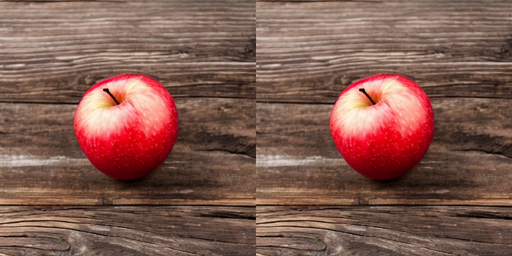

In [6]:
BASE_GUIDANCE = 7.5
BASE_STEPS    = 30

start = time.time()
ours = generate(
    "a red apple on a wooden table",
    tokenizer, text_encoder, unet, vae, scheduler,
    negative_prompt=NEG_PROMPT,
    guidance_scale=BASE_GUIDANCE,
    num_steps=BASE_STEPS,
    height=IMAGE_SIZE, width=IMAGE_SIZE,
    generator=make_generator(SEED, DEVICE),
)
print(f"Generated in {time.time() - start:.1f}s")

m1 = Image.open(REPO_ROOT / "outputs/milestone1_baseline/images/p1_simple_object.png").convert("RGB")
diff = np.abs(np.asarray(ours, dtype=np.float32) - np.asarray(m1, dtype=np.float32))
print(f"Mean pixel difference vs. M1: {diff.mean():.2f} | max: {diff.max():.0f}  (0–255 scale)")

side_by_side = Image.new("RGB", (IMAGE_SIZE * 2, IMAGE_SIZE))
side_by_side.paste(ours, (0, 0))
side_by_side.paste(m1, (IMAGE_SIZE, 0))
display(side_by_side.resize((IMAGE_SIZE, IMAGE_SIZE // 2)))   # left: ours | right: M1 pipeline

### Baseline conditional generation

In [7]:
from src.utils import make_grid, add_caption, save_run_log, write_gallery

PROMPTS = [
    ("p1_simple_object", "a red apple on a wooden table"),
    ("p2_multi_object",  "a cat and a dog sitting together on a park bench"),
    ("p3_spatial",       "a blue cube to the left of a yellow sphere on a white floor"),
    ("p4_stylistic",     "a mountain lake at sunrise, in the style of a watercolor painting"),
    ("p5_abstract",      "the feeling of nostalgia, surreal dreamlike digital art"),
]

RUNS = {}


def run_and_record(experiment, tag, prompt, *, guidance_scale=BASE_GUIDANCE,
                   num_steps=BASE_STEPS, sched=None, extra=None):
    sched = sched or scheduler
    start = time.time()
    img = generate(
        prompt, tokenizer, text_encoder, unet, vae, sched,
        negative_prompt=NEG_PROMPT,
        guidance_scale=guidance_scale,
        num_steps=num_steps,
        height=IMAGE_SIZE, width=IMAGE_SIZE,
        generator=make_generator(SEED, DEVICE),   # same seed for every image
    )
    seconds = round(time.time() - start, 2)

    (OUT_DIR / experiment).mkdir(exist_ok=True)
    rel_path = f"{experiment}/{tag}.png"
    img.save(OUT_DIR / rel_path)

    RUNS[rel_path] = {
        "experiment": experiment,
        "tag": tag,
        "prompt": prompt,
        "negative_prompt": NEG_PROMPT,
        "seed": SEED,
        "steps": num_steps,
        "guidance_scale": guidance_scale,
        "scheduler": type(sched).__name__,
        "height": IMAGE_SIZE,
        "width": IMAGE_SIZE,
        "seconds": seconds,
        "image": rel_path,
        **(extra or {}),
    }
    return img


def save_records():
    save_run_log(OUT_DIR, ENV, RUNS, model_id=MODEL_ID)
    write_gallery(OUT_DIR, RUNS, "Milestone 2 — Conditional generation")

In [8]:
baseline_images = []
for tag, prompt in PROMPTS:
    img = run_and_record("baseline", tag, prompt)
    baseline_images.append(img)
    print(f"[{RUNS[f'baseline/{tag}.png']['seconds']:>5.1f}s] {tag}")

baseline_grid = make_grid([add_caption(img, tag) for img, (tag, _) in zip(baseline_images, PROMPTS)],
                          cols=len(PROMPTS))
baseline_grid.save(OUT_DIR / "baseline" / "grid.png")
save_records()
print("Saved to", OUT_DIR / "baseline")

[  4.5s] p1_simple_object
[  4.5s] p2_multi_object
[  4.5s] p3_spatial
[  4.5s] p4_stylistic
[  4.6s] p5_abstract
Saved to /content/DLAI/generative/outputs/milestone2_conditioning/baseline


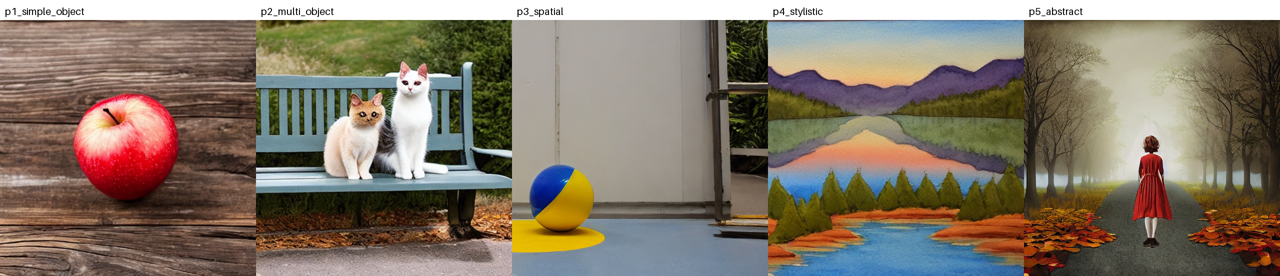

In [9]:
display(baseline_grid.resize((baseline_grid.width // 2, baseline_grid.height // 2)))

### Classifier-free guidance sweep
The five prompts at s = 1.0, 3.0, 5.0, 7.5, 10.0 and 15.0, with every other setting as in the baseline (PNDM, 30 steps, seed 42, negative prompt). Writes the images and `grid.png` to `outputs/milestone2_conditioning/guidance_sweep/` and adds the runs to `run_log.json` and `GALLERY.md`.

In [10]:
GUIDANCE_SCALES = [1.0, 3.0, 5.0, 7.5, 10.0, 15.0]

guidance_images = []
for tag, prompt in PROMPTS:
    for s in GUIDANCE_SCALES:
        img = run_and_record("guidance_sweep", f"{tag}_cfg{s}", prompt, guidance_scale=s)
        guidance_images.append(add_caption(img, f"{tag} · cfg {s}"))
        print(f"[{RUNS[f'guidance_sweep/{tag}_cfg{s}.png']['seconds']:>5.1f}s] {tag} cfg {s}")

guidance_grid = make_grid(guidance_images, cols=len(GUIDANCE_SCALES))
guidance_grid.save(OUT_DIR / "guidance_sweep" / "grid.png")
save_records()
print("Saved to", OUT_DIR / "guidance_sweep")

[  4.6s] p1_simple_object cfg 1.0
[  4.6s] p1_simple_object cfg 3.0
[  4.7s] p1_simple_object cfg 5.0
[  4.7s] p1_simple_object cfg 7.5
[  4.7s] p1_simple_object cfg 10.0
[  4.7s] p1_simple_object cfg 15.0
[  4.8s] p2_multi_object cfg 1.0
[  4.8s] p2_multi_object cfg 3.0
[  4.8s] p2_multi_object cfg 5.0
[  4.8s] p2_multi_object cfg 7.5
[  4.9s] p2_multi_object cfg 10.0
[  4.9s] p2_multi_object cfg 15.0
[  4.9s] p3_spatial cfg 1.0
[  4.9s] p3_spatial cfg 3.0
[  4.9s] p3_spatial cfg 5.0
[  4.9s] p3_spatial cfg 7.5
[  4.9s] p3_spatial cfg 10.0
[  4.9s] p3_spatial cfg 15.0
[  4.9s] p4_stylistic cfg 1.0
[  4.9s] p4_stylistic cfg 3.0
[  4.8s] p4_stylistic cfg 5.0
[  4.8s] p4_stylistic cfg 7.5
[  4.8s] p4_stylistic cfg 10.0
[  4.8s] p4_stylistic cfg 15.0
[  4.8s] p5_abstract cfg 1.0
[  4.8s] p5_abstract cfg 3.0
[  4.8s] p5_abstract cfg 5.0
[  4.8s] p5_abstract cfg 7.5
[  4.8s] p5_abstract cfg 10.0
[  4.9s] p5_abstract cfg 15.0
Saved to /content/DLAI/generative/outputs/milestone2_conditioning/

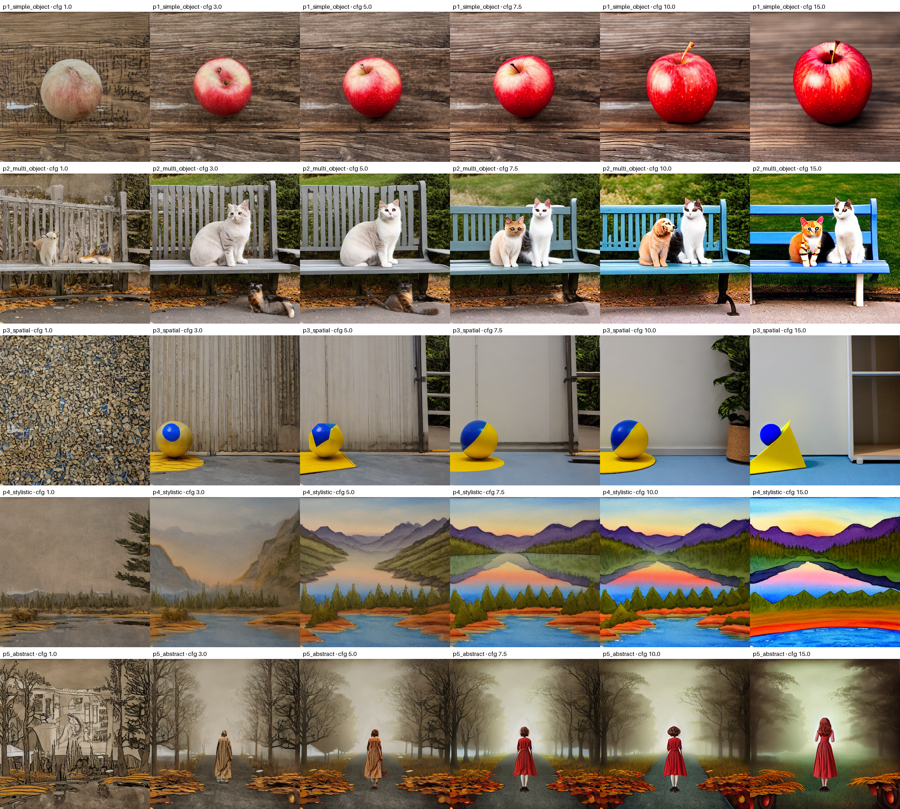

In [11]:
# Rows = prompts, columns = guidance scale
preview = guidance_grid.copy()
preview.thumbnail((900, 900))
display(preview)

### Noise schedule / sampler sweep
The five baseline prompts through PNDM, DDIM and DPM-Solver (`src/schedulers.py`) with seed, steps and guidance fixed. Writes images, `grid.png`, `run_log.json` and `GALLERY.md` to `outputs/milestone2_conditioning/noise_sweep/`.

In [12]:
# ============================================================
# M2 — Noise-schedule / sampler sweep  (PNDM vs DDIM vs DPM-Solver)
# Varies ONLY the sampler. Prompts, seed, steps and guidance are read from
# the baseline run log and kept identical across samplers. Run without a
# negative prompt (the baseline above uses NEG_PROMPT), so the PNDM images
# are not pixel-identical to the baseline. Writes to its own noise_sweep/
# folder; nothing existing is overwritten.
# ============================================================
import json, time, torch
from src import utils as U
from src import pipeline as P
from src import schedulers as S

DEVICE, DTYPE = U.get_device()
print("Device:", DEVICE, DTYPE)

# Pull the 5 baseline prompts + their exact settings from the committed log
m2_dir = U.milestone_dir("milestone2_conditioning")
blog = json.loads((m2_dir / "run_log.json").read_text())
MODEL_ID = blog.get("model_id", "stable-diffusion-v1-5/stable-diffusion-v1-5")

base = {}
for r in blog.get("runs", []):
    key = r["tag"].split("_cfg")[0]        # strip any guidance-sweep suffix
    if key not in base:
        base[key] = {
            "prompt":   r["prompt"],
            "seed":     int(r.get("seed", 42)),
            "steps":    int(r.get("steps", 30)),
            "guidance": float(r.get("guidance_scale", 7.5)),
        }
print(f"Loaded {len(base)} baseline prompts:", list(base))

SWEEP = ["pndm", "ddim", "dpm"]            # >=3 samplers; pndm == baseline reference

# Load model once
tokenizer, text_encoder = P.load_text_encoder(MODEL_ID, DEVICE, DTYPE)
unet, vae, _ = P.load_diffusion_components(MODEL_ID, DEVICE, DTYPE)

out_dir = m2_dir / "noise_sweep"
out_dir.mkdir(parents=True, exist_ok=True)

runs, grid_imgs = {}, []
for key, cfg in base.items():
    for name in SWEEP:
        sched = S.load_scheduler(name, MODEL_ID)      # fresh scheduler per image
        gen = U.make_generator(cfg["seed"], DEVICE)   # identical starting noise
        t0 = time.time()
        img = P.generate(
            cfg["prompt"], tokenizer, text_encoder, unet, vae, sched,
            negative_prompt="",   # as run; baseline uses NEG_PROMPT
            guidance_scale=cfg["guidance"], num_steps=cfg["steps"], generator=gen,
        )
        dt = round(time.time() - t0, 2)
        tag, fname = f"{key}_{name}", f"{key}_{name}.png"
        img.save(out_dir / fname)
        grid_imgs.append(U.add_caption(img, f"{key} | {name}"))
        runs[tag] = {
            "experiment": "noise_sweep", "tag": tag, "prompt": cfg["prompt"],
            "scheduler": name, "steps": cfg["steps"],
            "guidance_scale": cfg["guidance"], "seed": cfg["seed"],
            "seconds": dt, "image": fname,
        }
        print(f"  {tag}  ({dt}s)")

U.make_grid(grid_imgs, cols=len(SWEEP)).save(out_dir / "grid.png")
env = U.environment_info(DEVICE, DTYPE)
U.save_run_log(out_dir, env, runs, experiment="noise_sweep",
               model_id=MODEL_ID, samplers=SWEEP)
U.write_gallery(out_dir, runs, "M2 - Noise-schedule / sampler sweep")
print(f"\nDone: {len(runs)} images -> {out_dir}")

Device: cuda torch.float16
Loaded 5 baseline prompts: ['p1_simple_object', 'p2_multi_object', 'p3_spatial', 'p4_stylistic', 'p5_abstract']
  p1_simple_object_pndm  (4.85s)
  p1_simple_object_ddim  (4.68s)
  p1_simple_object_dpm  (4.74s)
  p2_multi_object_pndm  (4.9s)
  p2_multi_object_ddim  (4.8s)
  p2_multi_object_dpm  (4.79s)
  p3_spatial_pndm  (4.97s)
  p3_spatial_ddim  (4.8s)
  p3_spatial_dpm  (4.74s)
  p4_stylistic_pndm  (4.9s)
  p4_stylistic_ddim  (4.73s)
  p4_stylistic_dpm  (4.68s)
  p5_abstract_pndm  (4.84s)
  p5_abstract_ddim  (4.68s)
  p5_abstract_dpm  (4.67s)

Done: 15 images -> /content/DLAI/generative/outputs/milestone2_conditioning/noise_sweep


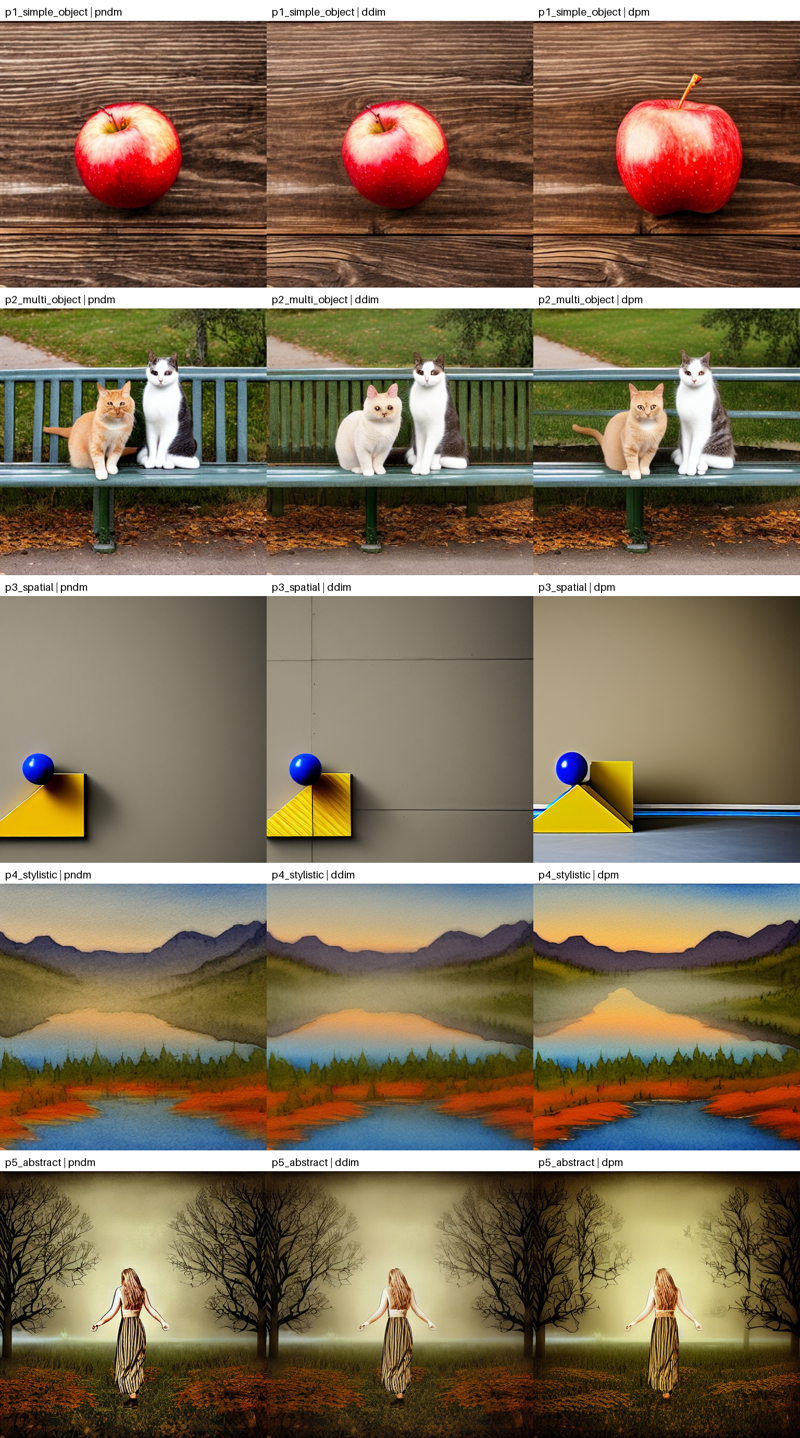

In [13]:
# Preview the sampler-sweep grid (rows = prompts, columns = PNDM / DDIM / DPM-Solver)
from IPython.display import display
from PIL import Image
grid = Image.open(out_dir / "grid.png")
grid.thumbnail((800, 1440))
display(grid)